# RQ3 Analysis: ROUGE Scores

Computes the ROUGE scores (ROUGE-1, ROUGE-2, ROUGE-L) of AI-generated PR descriptions compared to their human-written counterparts.

- Uses the `rouge-score` package.
- ROUGE-1 evaluates unigrams, ROUGE-2 evaluates bigrams, and ROUGE-L evaluates the Longest Common Subsequence.
- Aggregates the Mean and Median for Precision, Recall, and F1-Score for each ROUGE variant.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from rouge_score import rouge_scorer
import os

In [2]:
# Set consistent plotting style
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Data Loading & Preparation

In [3]:
csv_path = '/mnt/ext-hdd1/ayo/llm-in-prs/phase3/datasets/temperature_1/run_3_corrected_detection_v1/corpus.csv'
df = pd.read_csv(csv_path)

In [4]:
variation_map = {
    'P-1': 'Repo Path',
    'P-2': 'PR Title',
    'P-3': 'File Diff',      # Baseline
    'P-4': 'File Contents',
    'P-5': 'Linked Issue',
    'P-6': 'Without File Contents'
}
df['Context_Name'] = df['variation'].map(variation_map)
df['normalized_pr_id'] = df['pr_id'].astype(str)

In [5]:
# FILTERING: Keep only paired PRs
ai_pr_ids = set(df[df['entry_type'] == 'ai']['normalized_pr_id'].unique())
human_pr_ids = set(df[df['entry_type'] == 'human']['normalized_pr_id'].unique())
valid_ids = ai_pr_ids.intersection(human_pr_ids)

In [6]:
# Human subset
human_df = df[(df['entry_type'] == 'human') & (df['normalized_pr_id'].isin(valid_ids))].copy()
human_df['model'] = 'Human'

# Prepare a mapping from pr_id to human_text for reference matching
human_text_map = human_df.set_index('normalized_pr_id')['text'].to_dict()

In [7]:
# AI subset
ai_df = df[(df['entry_type'] == 'ai') & (df['normalized_pr_id'].isin(valid_ids))].copy()

# Add the corresponding human reference text to each AI entry
ai_df['reference_text'] = ai_df['normalized_pr_id'].map(human_text_map)

In [8]:
print(f"Paired PR Count: {len(valid_ids)}")
print(f"Models found: {ai_df['model'].unique()}")
print(f"Human entries: {len(human_df)}, AI entries: {len(ai_df)}")

Paired PR Count: 308
Models found: ['Qwen/Qwen2.5-72B-Instruct' 'gpt-5-mini-2025-08-07'
 'meta-llama/llama-3.1-70b-instruct']
Human entries: 308, AI entries: 5322


## 2. Compute ROUGE Scores

In [9]:
scorer = rouge_scorer.RougeScorer(['rouge1', 'rouge2', 'rougeL'], use_stemmer=True)

def compute_rouge(row):
    ref = str(row['reference_text']) if not pd.isna(row['reference_text']) else ""
    cand = str(row['text']) if not pd.isna(row['text']) else ""
    
    if not ref.strip() or not cand.strip():
        return pd.Series({
            'rouge1_precision': np.nan, 'rouge1_recall': np.nan, 'rouge1_fmeasure': np.nan,
            'rouge2_precision': np.nan, 'rouge2_recall': np.nan, 'rouge2_fmeasure': np.nan,
            'rougeL_precision': np.nan, 'rougeL_recall': np.nan, 'rougeL_fmeasure': np.nan,
        })
    
    scores = scorer.score(ref, cand)
    
    return pd.Series({
        'rouge1_precision': scores['rouge1'].precision,
        'rouge1_recall': scores['rouge1'].recall,
        'rouge1_fmeasure': scores['rouge1'].fmeasure,
        'rouge2_precision': scores['rouge2'].precision,
        'rouge2_recall': scores['rouge2'].recall,
        'rouge2_fmeasure': scores['rouge2'].fmeasure,
        'rougeL_precision': scores['rougeL'].precision,
        'rougeL_recall': scores['rougeL'].recall,
        'rougeL_fmeasure': scores['rougeL'].fmeasure,
    })

In [10]:
# We only calculate ROUGE for the AI subset since they are compared against the human reference
print("Computing ROUGE metrics...")
rouge_cols = [
    'rouge1_precision', 'rouge1_recall', 'rouge1_fmeasure',
    'rouge2_precision', 'rouge2_recall', 'rouge2_fmeasure',
    'rougeL_precision', 'rougeL_recall', 'rougeL_fmeasure'
]
ai_df[rouge_cols] = ai_df.apply(compute_rouge, axis=1)

Computing ROUGE metrics...


In [11]:
# Filter out rows where calculation failed (due to empty strings)
ai_df = ai_df.dropna(subset=rouge_cols)

print("ROUGE metrics computed.")
print(f"AI dataset size with computed metrics: {len(ai_df)}")
display(ai_df[['entry_type', 'model', 'rouge1_fmeasure', 'rouge2_fmeasure', 'rougeL_fmeasure']].head(10))

ROUGE metrics computed.
AI dataset size with computed metrics: 5322


,entry_type,model,rouge1_fmeasure,rouge2_fmeasure,rougeL_fmeasure
0,ai,Qwen/Qwen2.5-72B-Instruct,0.130081,0.033058,0.130081
1,ai,Qwen/Qwen2.5-72B-Instruct,0.089286,0.000000,0.053571
2,ai,Qwen/Qwen2.5-72B-Instruct,0.149660,0.000000,0.095238
3,ai,Qwen/Qwen2.5-72B-Instruct,0.056338,0.000000,0.042254
4,ai,Qwen/Qwen2.5-72B-Instruct,0.126582,0.000000,0.088608
5,ai,Qwen/Qwen2.5-72B-Instruct,0.116788,0.014815,0.058394
6,ai,Qwen/Qwen2.5-72B-Instruct,0.170213,0.021739,0.127660
7,ai,Qwen/Qwen2.5-72B-Instruct,0.066667,0.000000,0.044444
8,ai,Qwen/Qwen2.5-72B-Instruct,0.144928,0.000000,0.101449
9,ai,Qwen/Qwen2.5-72B-Instruct,0.091503,0.000000,0.078431


## 3. ROUGE-L Boxplots by Context per LLM

This mirrors the plotting design used in other RQ3 notebooks:

- One panel per LLM model (stacked vertically).
- Each panel includes the 6 AI context boxplots.
- No Human boxplot is included in this view.

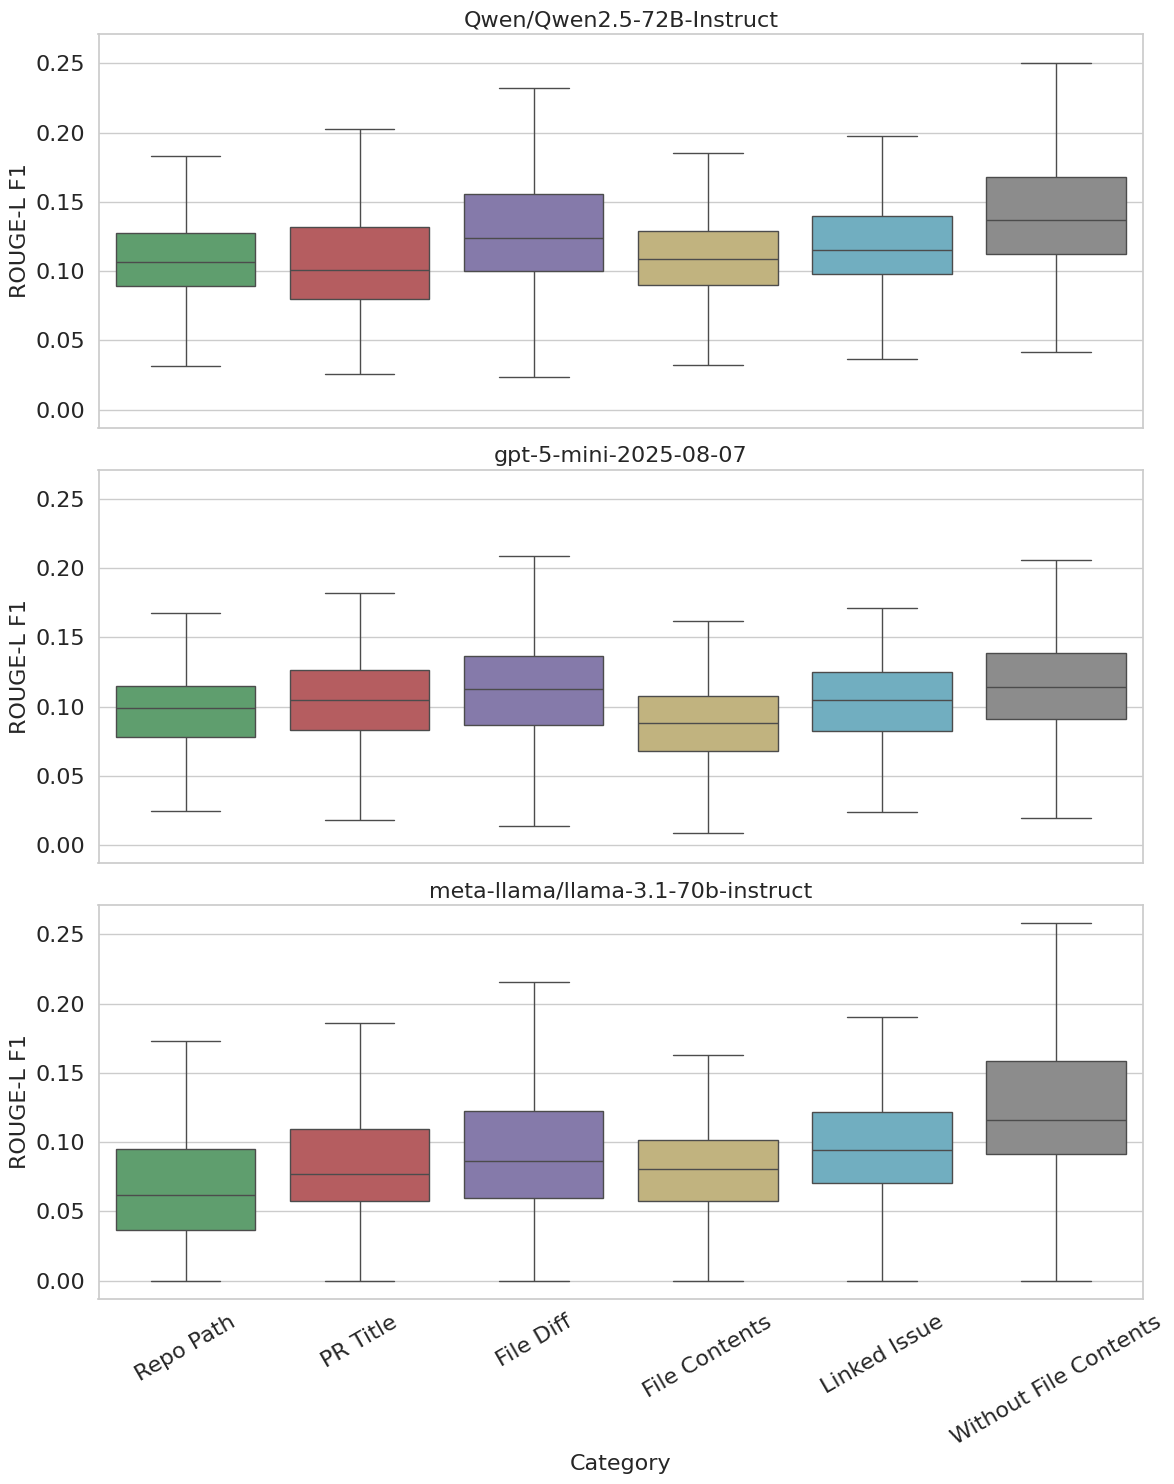

In [12]:
context_order = ['Repo Path', 'PR Title', 'File Diff', 'File Contents', 'Linked Issue', 'Without File Contents']
llm_models = ai_df['model'].dropna().unique().tolist()
x_order = context_order
palette_map = {
    'Repo Path': '#55A868',
    'PR Title': '#C44E52',
    'File Diff': '#8172B2',
    'File Contents': '#CCB974',
    'Linked Issue': '#64B5CD',
    'Without File Contents': '#8C8C8C'
}

fig, axes = plt.subplots(len(llm_models), 1, figsize=(12, 5 * len(llm_models)), sharex=True, sharey=True)
if len(llm_models) == 1:
    axes = [axes]

for i, model in enumerate(llm_models):
    ax = axes[i]
    ax.set_title(model, fontsize=16)

    panel_df = ai_df[ai_df['model'] == model][['rougeL_fmeasure', 'Context_Name']].dropna().copy()
    panel_df['Category'] = panel_df['Context_Name']

    sns.boxplot(
        data=panel_df,
        x='Category',
        y='rougeL_fmeasure',
        order=x_order,
        hue='Category',
        hue_order=x_order,
        ax=ax,
        palette=palette_map,
        dodge=False,
        legend=False,
        showfliers=False
    )

    ax.set_xlabel('Category' if i == len(llm_models) - 1 else '', fontsize=16)
    ax.set_ylabel('ROUGE-L F1', fontsize=16)
    ax.tick_params(axis='x', rotation=30, labelsize=16)
    ax.tick_params(axis='y', labelsize=16)

plt.tight_layout()
from pathlib import Path
Path('outputs/figures_pdf').mkdir(parents=True, exist_ok=True)
plt.savefig(str(Path('outputs/figures_pdf') / 'rouge.pdf'), bbox_inches='tight', dpi=150)
plt.show()

## 3. Final RQ3 Answer: Human Baseline Comparison (ROUGE)

This section directly answers the core RQ3 objective using paired AI↔Human ROUGE results.

- **Reference**: Original human-written PR descriptions (`n=308`, paired PR set).
- **Candidates**: AI descriptions for each model and context (P-1 ... P-6).
- **Reported**: Mean/Median ROUGE F1 per [Model, Context], Cliff's δ vs Human Baseline (ROUGE-L), and ranking by highest ROUGE-L Median F1.

In [13]:
# Corrected generated-to-reference summary; human self-comparisons are not a baseline.
from pathlib import Path

row_dir = Path('outputs/row_level')
row_dir.mkdir(parents=True, exist_ok=True)
row_cols = [
    'normalized_pr_id', 'entry_type', 'model', 'variation', 'Context_Name',
    'rouge1_precision', 'rouge1_recall', 'rouge1_fmeasure',
    'rouge2_precision', 'rouge2_recall', 'rouge2_fmeasure',
    'rougeL_precision', 'rougeL_recall', 'rougeL_fmeasure',
]
row_scores = ai_df[row_cols].sort_values(
    ['model', 'variation', 'normalized_pr_id'], kind='stable'
)
row_scores.to_csv(row_dir / 'rouge_metrics.csv', index=False)

summary = (
    row_scores.groupby(['model', 'variation', 'Context_Name'], as_index=False)
    .agg(
        n=('normalized_pr_id', 'size'),
        rouge1_mean=('rouge1_fmeasure', 'mean'),
        rouge1_median=('rouge1_fmeasure', 'median'),
        rouge2_mean=('rouge2_fmeasure', 'mean'),
        rouge2_median=('rouge2_fmeasure', 'median'),
        rougeL_mean=('rougeL_fmeasure', 'mean'),
        rougeL_median=('rougeL_fmeasure', 'median'),
    )
    .rename(columns={'Context_Name': 'context'})
)
summary = summary.sort_values(['model', 'variation'], kind='stable')
best = (
    summary.sort_values(
        ['model', 'rougeL_median', 'rougeL_mean'],
        ascending=[True, False, False],
        kind='stable',
    )
    .groupby('model', as_index=False)
    .first()
)
summary.to_csv('outputs/rq2_rouge_generated_to_reference_summary.csv', index=False)
best.to_csv('outputs/rq2_rouge_best_context.csv', index=False)
display(summary)
display(best)
print('Saved generated-to-reference ROUGE summaries without a human-self baseline.')


,model,variation,context,n,rouge1_mean,rouge1_median,rouge2_mean,rouge2_median,rougeL_mean,rougeL_median
0,Qwen/Qwen2.5-72B-Instruct,P-1,Repo Path,308,0.184774,0.186586,0.024094,0.024742,0.106666,0.106575
1,Qwen/Qwen2.5-72B-Instruct,P-2,PR Title,308,0.174954,0.174661,0.030905,0.026667,0.108204,0.100947
2,Qwen/Qwen2.5-72B-Instruct,P-3,File Diff,308,0.227082,0.231319,0.042156,0.033149,0.128803,0.124123
3,Qwen/Qwen2.5-72B-Instruct,P-4,File Contents,302,0.197300,0.205847,0.022877,0.020654,0.107601,0.108599
4,Qwen/Qwen2.5-72B-Instruct,P-5,Linked Issue,273,0.211667,0.218182,0.034642,0.031532,0.118300,0.115385
5,Qwen/Qwen2.5-72B-Instruct,P-6,Without File Contents,273,0.250915,0.257840,0.053503,0.046243,0.139323,0.136585
6,gpt-5-mini-2025-08-07,P-1,Repo Path,308,0.185283,0.194083,0.016333,0.014555,0.094398,0.098859
7,gpt-5-mini-2025-08-07,P-2,PR Title,308,0.193874,0.206012,0.021844,0.016989,0.103223,0.105110
8,gpt-5-mini-2025-08-07,P-3,File Diff,308,0.210513,0.219381,0.028602,0.022069,0.111681,0.112676
9,gpt-5-mini-2025-08-07,P-4,File Contents,302,0.169210,0.176002,0.015433,0.010681,0.086669,0.087894


,model,variation,context,n,rouge1_mean,rouge1_median,rouge2_mean,rouge2_median,rougeL_mean,rougeL_median
0,Qwen/Qwen2.5-72B-Instruct,P-6,Without File Contents,273,0.250915,0.257840,0.053503,0.046243,0.139323,0.136585
1,gpt-5-mini-2025-08-07,P-6,Without File Contents,273,0.221660,0.231760,0.034545,0.029685,0.113227,0.114428
2,meta-llama/llama-3.1-70b-instruct,P-6,Without File Contents,273,0.205388,0.193798,0.040512,0.025316,0.128561,0.115942


Saved generated-to-reference ROUGE summaries without a human-self baseline.
